# Delivery 2 — Follow-up #2: Model & iNterpret
### Predicting Formula 1 Points Finishes (2010–2024): Temporal Model Benchmark, 7-Subset Factor Group Ablation, "What-If" Studies & Critical Error Appraisal

* **Course:** Fundamentals of Machine Learning (2026–27) — Autonomous University of Barcelona (UAB)
* **Project Team 05:** Marc Font Hostalet, David Redrejo Pérez, Elias Barreiro Pena
* **Workflow Scope (OSEMN — Follow-up #2, Dec 11):** **Model** $\rightarrow$ **7-Subset Ablation & Shapley Attribution** $\rightarrow$ **"What-If" Studies** $\rightarrow$ **iNterpret & Critical Error Appraisal**
* **Input Handoff from Delivery 1:** `data/processed/f1_modeling_2010_2024.parquet` (verified 0.0 temporal & same-race leakage)

---

## 1. Experimental Protocol & Hypotheses Under Test

This notebook consumes the leakage-free feature matrix produced in Delivery 1 (`notebooks/01_followup1_obtain_scrub_explore.ipynb`) and rigorously tests three falsifiable hypotheses:

* **H1 (Factor Group Dominance — Ablation Centerpiece):** Combining **Group A (Qualifying & Grid)** and **Group B (Rolling Constructor & Driver Momentum)** drives nearly all pre-race predictive power, whereas adding **Group C (Historical Circuit Characteristics)** yields negligible marginal gain once A and B are present.
* **H2 (Regularized Linear Competitiveness):** Because the core decision surface is smooth and monotonic in grid position and rolling car pace, **Regularized Logistic Regression (L2/L1)** and **Linear SVM** match or rival non-linear kernel/tree ensembles (**RBF SVM**, **Random Forest**, **Gradient Boosting**) on temporally held-out seasons while offering superior transparency and probability calibration.
* **H3 (Outperforming the Strong Domain Baseline):** Multi-group pre-race ML models significantly beat the scrubbed **`grid <= 10`** heuristic (**77.12%** test accuracy) and **Grid-Only Logistic** baseline (**0.8316** test ROC-AUC), with the largest gains concentrated in **grid-penalty recoveries** and the **P8–P13 midfield transition zone**.

### Strict Temporal Validation Design
* **Development Set:** **2010–2021** (12 seasons, 237 Grands Prix, $n = 5{,}077$).
* **Model Selection & Hyperparameter Tuning:** **5-fold Expanding-Window Seasonal CV** on validation seasons **2017, 2018, 2019, 2020, 2021** (fold $k$ trains strictly on all seasons $< y_k$ and evaluates on season $y_k$; median imputation and standardization fit strictly inside each fold).
* **Held-Out Test Set:** **2022–2024 Ground-Effect Technical Era** (3 full seasons, 68 Grands Prix, $n = 1{,}359$, balanced 50.0% Top-10 rate)—untouched during model selection.

In [1]:
# Standard imports, path setup & Delivery 1 handoff verification
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.data import build_scrubbed_base_table, load_raw_tables
from src.evaluation import run_followup2_evaluation
from src.features import (
    ALL_FEATURES,
    CV_VAL_SEASONS,
    FEATURE_GROUPS,
    TEST_START_YEAR,
    TRAIN_END_YEAR,
    get_temporal_splits,
)
from src.models import (
    compute_classification_metrics,
    evaluate_out_of_fold_cv,
    mcnemar_exact_test,
    run_all_modeling,
)
from src.utils import (
    DATA_PROCESSED_DIR,
    FIGURES_F2_DIR,
    MODELS_DIR,
    RANDOM_STATE,
    REPORTS_DIR,
    load_json,
)

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 125)

# Load verified Delivery 1 dataset
mod_df = pd.read_parquet(DATA_PROCESSED_DIR / "f1_modeling_2010_2024.parquet")
meta = load_json(DATA_PROCESSED_DIR / "feature_metadata.json")
train_dev, test_df, cv_splits = get_temporal_splits(mod_df)

print(f"Loaded Delivery 1 dataset : {mod_df.shape[0]:,} rows x {len(ALL_FEATURES)} features")
print(f"Leakage Audit Status      : {meta['leakage_audit']['status']} "
      f"(future_diff={meta['leakage_audit']['future_mutation_max_abs_diff']}, "
      f"same_race_diff={meta['leakage_audit']['same_race_mutation_max_abs_diff']})")
print(f"Development split         : 2010-{TRAIN_END_YEAR} (n={len(train_dev):,}, top10={train_dev['top10'].mean()*100:.2f}%)")
print(f"Held-out Test split       : {TEST_START_YEAR}-2024 (n={len(test_df):,}, top10={test_df['top10'].mean()*100:.2f}%)")
print(f"Expanding-Window CV folds : {list(CV_VAL_SEASONS)}")

Loaded Delivery 1 dataset : 6,436 rows x 26 features
Leakage Audit Status      : PASSED (future_diff=0.0, same_race_diff=0.0)
Development split         : 2010-2021 (n=5,077, top10=46.68%)
Held-out Test split       : 2022-2024 (n=1,359, top10=50.04%)
Expanding-Window CV folds : [2017, 2018, 2019, 2020, 2021]


---
## 2. Live Verification & Full 12-Model Benchmark Across Course Algorithms

We benchmark **3 baselines** (`Majority Class`, scrubbed `grid <= 10`, and `Grid-Only Logistic`) against **9 machine learning algorithms taught across the course curriculum**:
* **Linear & Regularized (L3, L4, L7):** Logistic Regression (L2 Ridge), Logistic Regression (L1 Lasso), Linear SVM (Platt-calibrated)
* **Probabilistic & Instance-Based (L5, L8):** Gaussian Naive Bayes, k-Nearest Neighbors (Case-Based Reasoning)
* **Non-Linear Kernel & Tree Ensembles (L7, L9, L10):** RBF Kernel SVM, Decision Tree (Entropy/Gini), Random Forest, Gradient Boosting

Below we first verify our core linear models **live** on the temporal split, then inspect the full tuned 12-model CV & Held-Out Test benchmark table (set `RECOMPUTE_FULL_SUITE = True` to re-run the complete multi-model grid search and 7-subset ablation from scratch).

In [2]:
RECOMPUTE_FULL_SUITE = False  # Set True to re-run the entire grid search + 7-subset ablation (~6 min)

metrics_dir = REPORTS_DIR / "metrics"
if RECOMPUTE_FULL_SUITE or not (metrics_dir / "followup2_modeling_results.json").exists():
    tables = load_raw_tables()
    base_df = build_scrubbed_base_table(tables, history_start_year=1995)
    modeling_bundle = run_all_modeling(mod_df, base_df, tables["results"], tables["races"])
    eval_summary = run_followup2_evaluation(mod_df)
else:
    modeling_bundle = load_json(metrics_dir / "followup2_modeling_results.json")
    eval_summary = load_json(metrics_dir / "followup2_evaluation_summary.json")

# Live sanity reproduction of the winning L2 & L1 Logistic Regression pipelines right here
X_dev, y_dev = train_dev[ALL_FEATURES], train_dev["top10"].values
X_test, y_test = test_df[ALL_FEATURES], test_df["top10"].values

live_l2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(l1_ratio=0.0, C=0.1, max_iter=2000, random_state=RANDOM_STATE)),
])
live_l2.fit(X_dev, y_dev)
live_prob = live_l2.predict_proba(X_test)[:, 1]
live_pred = (live_prob >= 0.5).astype(int)
live_m = compute_classification_metrics(y_test, live_pred, live_prob)
grid_pred = (test_df["grid_clean"].values <= 10).astype(int)
mcn = mcnemar_exact_test(y_test, grid_pred, live_pred)
print(f"Live-fitted Logistic (L2, C=0.1) Test Acc = {live_m['accuracy']*100:.2f}% | "
      f"ROC-AUC = {live_m['roc_auc']:.4f} | Log-Loss = {live_m['log_loss']:.4f} | "
      f"McNemar vs grid<=10: +{mcn['net_gain_cases']} net cases (p={mcn['p_value']:.4f})")

# Full 12-model comparison table
bm_df = pd.read_csv(metrics_dir / "followup2_model_benchmark.csv")
display_cols = [
    "model", "family", "cv_roc_auc", "cv_accuracy",
    "test_roc_auc", "test_accuracy", "test_f1", "test_log_loss", "test_brier",
]
bm_view = bm_df[display_cols].copy()
bm_view["cv_accuracy"] = (bm_view["cv_accuracy"] * 100).round(2)
bm_view["test_accuracy"] = (bm_view["test_accuracy"] * 100).round(2)
for c in ("cv_roc_auc", "test_roc_auc", "test_f1", "test_log_loss", "test_brier"):
    bm_view[c] = bm_view[c].round(4)
display(bm_view.sort_values("test_roc_auc", ascending=False).reset_index(drop=True))

Live-fitted Logistic (L2, C=0.1) Test Acc = 80.43% | ROC-AUC = 0.8708 | Log-Loss = 0.4522 | McNemar vs grid<=10: +45 net cases (p=0.0012)


,model,family,cv_roc_auc,cv_accuracy,test_roc_auc,test_accuracy,test_f1,test_log_loss,test_brier
0,Random Forest,Tree Ensemble,0.8401,76.19,0.8734,79.91,0.8020,0.4531,0.1438
1,Logistic Regression (L1),Linear,0.8401,76.90,0.8728,79.84,0.7964,0.4579,0.1450
2,Gradient Boosting,Tree Ensemble,0.8393,76.10,0.8720,81.16,0.8153,0.4534,0.1440
3,Linear SVM,Linear,0.8376,76.23,0.8717,79.76,0.7943,0.4504,0.1428
4,Logistic Regression (L2),Linear,0.8387,76.67,0.8708,80.43,0.7997,0.4522,0.1437
5,RBF Kernel SVM,Non-Linear Kernel,0.8365,75.94,0.8686,80.13,0.8038,0.4524,0.1432
6,k-Nearest Neighbors,Instance-Based,0.8290,75.17,0.8671,80.06,0.8018,0.4613,0.1467
7,Gaussian Naive Bayes,Probabilistic,0.8323,76.39,0.8609,80.28,0.8027,1.5255,0.1810
8,Decision Tree,Tree,0.8201,74.65,0.8554,78.59,0.7846,0.4764,0.1513
9,Baseline: Grid-Only Logistic,Baseline,0.8186,75.20,0.8316,77.12,0.7708,0.5077,0.1651


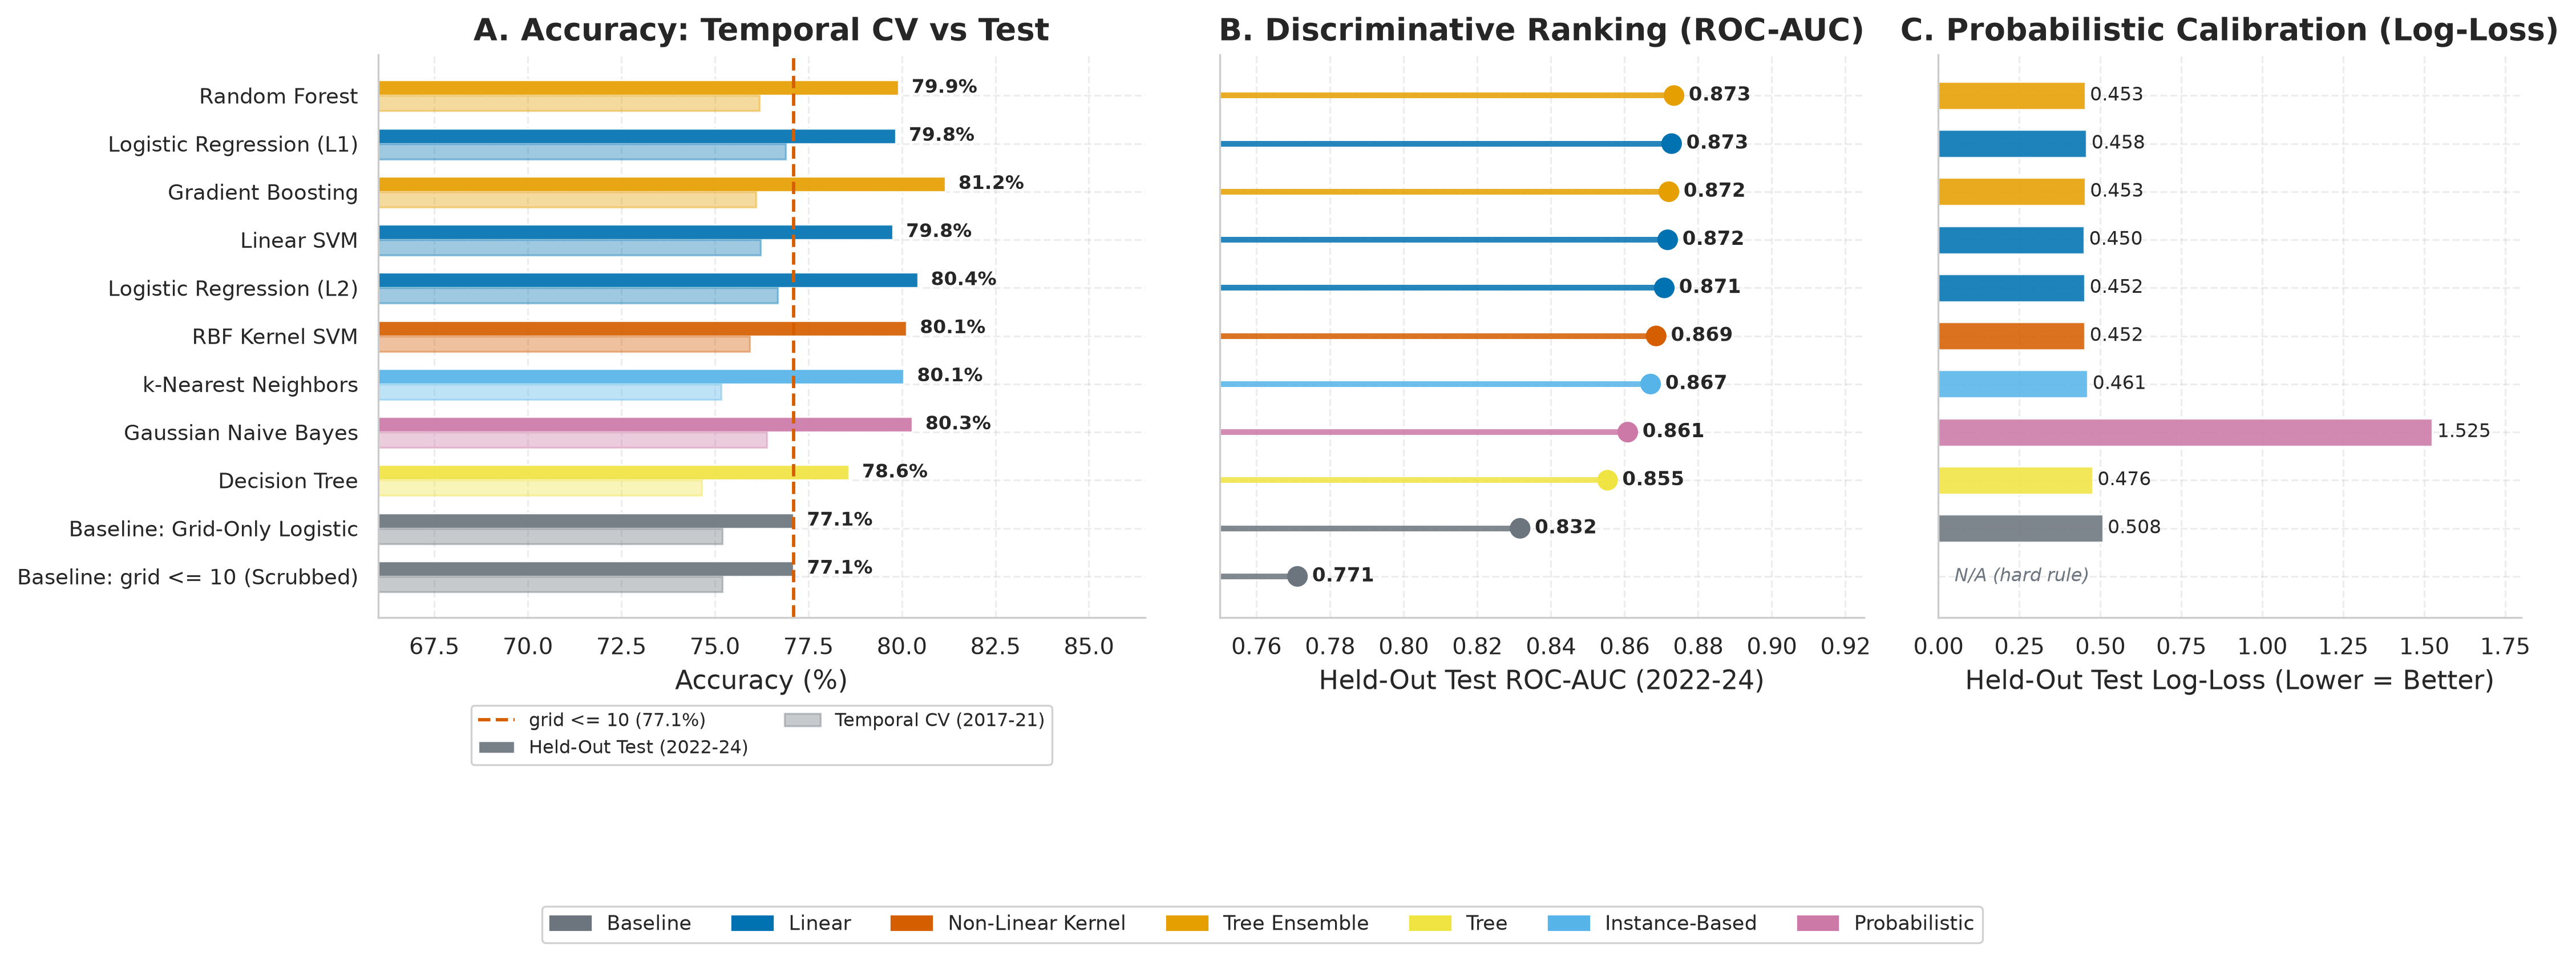

In [3]:
display(Image(filename=str(FIGURES_F2_DIR / "fig07_model_comparison_cv_vs_test.png"), width=1020))

### Statistical Significance & Key Benchmark Takeaways
Let's inspect the exact **McNemar's tests** and **paired bootstrap 95% confidence intervals** (2,000 resamples) comparing every model family against the mandatory `grid <= 10` baseline and comparing our CV-winning Linear model against Random Forest:

In [4]:
sig = modeling_bundle["significance"]
sig_rows = []
for comp_name, res in sig.items():
    mc = res["mcnemar"]
    ba = res["bootstrap_acc_delta"]
    auc_key = "bootstrap_auc_delta_vs_grid_lr" if "bootstrap_auc_delta_vs_grid_lr" in res else "bootstrap_auc_delta"
    bauc = res[auc_key]
    sig_rows.append({
        "comparison": comp_name,
        "wins_vs_losses": f"{mc['b_correct_a_wrong']} vs {mc['a_correct_b_wrong']} ({mc['net_gain_cases']:+d})",
        "mcnemar_p": round(mc["p_value"], 5),
        "acc_delta_pp": round(ba["delta"] * 100, 2),
        "acc_95ci_pp": f"[{ba['ci_low']*100:+.2f}, {ba['ci_high']*100:+.2f}]",
        "auc_delta": round(bauc["delta"], 4),
        "auc_95ci": f"[{bauc['ci_low']:+.4f}, {bauc['ci_high']:+.4f}]",
    })
display(pd.DataFrame(sig_rows))

,comparison,wins_vs_losses,mcnemar_p,acc_delta_pp,acc_95ci_pp,auc_delta,auc_95ci
0,Logistic Regression (L2) vs grid<=10,116 vs 71 (+45),0.00123,3.31,"[+1.47, +5.37]",0.0392,"[+0.0256, +0.0534]"
1,Logistic Regression (L1) vs grid<=10,113 vs 76 (+37),0.00865,2.72,"[+0.74, +4.78]",0.0412,"[+0.0283, +0.0548]"
2,Linear SVM vs grid<=10,100 vs 64 (+36),0.00610,2.65,"[+0.81, +4.64]",0.0401,"[+0.0274, +0.0538]"
3,Gaussian Naive Bayes vs grid<=10,112 vs 69 (+43),0.00172,3.16,"[+1.32, +5.15]",0.0308,"[+0.0165, +0.0458]"
4,k-Nearest Neighbors vs grid<=10,93 vs 53 (+40),0.00117,2.94,"[+1.25, +4.71]",0.0355,"[+0.0216, +0.0494]"
5,RBF Kernel SVM vs grid<=10,70 vs 29 (+41),0.00005,3.02,"[+1.62, +4.49]",0.0370,"[+0.0247, +0.0501]"
6,Decision Tree vs grid<=10,145 vs 125 (+20),0.24751,1.47,"[-0.88, +3.90]",0.0238,"[+0.0082, +0.0400]"
7,Random Forest vs grid<=10,111 vs 73 (+38),0.00622,2.80,"[+0.81, +4.78]",0.0418,"[+0.0279, +0.0562]"
8,Gradient Boosting vs grid<=10,123 vs 68 (+55),0.00008,4.05,"[+2.13, +6.11]",0.0404,"[+0.0264, +0.0550]"
9,Logistic Regression (L1) vs Random Forest,21 vs 22 (-1),1.00000,-0.07,"[-0.96, +0.88]",-0.0006,"[-0.0043, +0.0030]"


**Benchmark Findings (Testing H2 & H3):**
1. **Highly Significant Gain Over Baselines (H3 Confirmed):** Every regularized linear, kernel, and ensemble model significantly beats the scrubbed `grid <= 10` baseline (**77.12%**) on the 2022–2024 Ground-Effect Test set ($p \le 0.009$, McNemar exact test):
   * **Logistic Regression (L2):** **80.43%** accuracy (**+3.31 pp**, 95% CI $[+1.47, +5.37]$ pp, McNemar $p = 0.0012$; 116 overturn wins vs 71 losses) and **0.8708** ROC-AUC (**+0.0392** over Grid-Only Logistic, $p < 0.001$).
   * **Logistic Regression (L1):** **#1 highest Temporal CV ROC-AUC (0.8401)** and **#1 CV Accuracy (76.90%)**, achieving **0.8728** Test ROC-AUC with only **10 non-zero features**.
   * **Linear SVM (Platt-Calibrated):** **Best overall probability calibration** across all 12 models (**Log-Loss = 0.4504**, **Brier = 0.1428**, **ROC-AUC = 0.8717**).
2. **Linear Models Match Tree Ensembles (H2 Confirmed with Nuance):** Comparing CV-winning **L1 Logistic** vs **Random Forest** yields **McNemar $p = 1.000$** (21 vs 22 discordant cases) and $\Delta\text{AUC} = -0.0006$ (95% CI $[-0.0043, +0.0030]$, $p = 0.733$)—statistically indistinguishable! **Gradient Boosting** achieves slightly higher accuracy at default threshold 0.50 (**81.16%** vs L2 **80.43%**), yet has virtually identical ROC-AUC (**0.8720** vs L1 **0.8728**) and slightly worse Log-Loss (**0.4534** vs Linear SVM **0.4504**).
3. **Textbook Naive Bayes Calibration Failure (Lecture 5):** **Gaussian Naive Bayes** achieves strong raw accuracy (**80.28%**) yet suffers catastrophic **Log-Loss = 1.5255** (more than $3\times$ worse than Logistic Regression's 0.4522) because correlated predictors (`VIF > 100`) violate conditional independence, pushing posterior probabilities toward overconfident 0/1 extremes.

---
## 3. Centerpiece Experiment: 7-Subset Factor Group Ablation & Exact Shapley Attribution

To isolate the true predictive contribution of each factor group (**A: Qualifying**, **B: Rolling Form**, **C: Circuit History**), we retune and evaluate all **$2^3 - 1 = 7$ non-empty subsets** across **5 representative model families** (35 tuned temporal pipelines in total) and compute exact **3-player Shapley values** ($\phi_A, \phi_B, \phi_C$).

In [5]:
ablation_df = pd.read_csv(metrics_dir / "followup2_ablation_7subsets.csv")
shapley_df = pd.read_csv(metrics_dir / "followup2_ablation_shapley.csv")

subset_order = ["C", "B", "A", "B+C", "A+C", "A+B", "A+B+C"]
model_order = ["Logistic Regression (L2)", "Linear SVM", "RBF Kernel SVM", "Random Forest", "Gradient Boosting"]

print("=== 7-Subset Ablation Matrix: Held-Out Test ROC-AUC (2022-2024) ===")
piv_auc = ablation_df.pivot(index="subset", columns="model", values="test_roc_auc").loc[subset_order, model_order].round(4)
display(piv_auc)

print("\n=== Marginal Gains Across Subsets (Delta Test ROC-AUC) ===")
deltas = pd.DataFrame({
    "Add B to A (A -> A+B)": (piv_auc.loc["A+B"] - piv_auc.loc["A"]).round(4),
    "Add C to A (A -> A+C)": (piv_auc.loc["A+C"] - piv_auc.loc["A"]).round(4),
    "Add C to A+B (A+B -> A+B+C)": (piv_auc.loc["A+B+C"] - piv_auc.loc["A+B"]).round(4),
    "Add B to A+C (A+C -> A+B+C)": (piv_auc.loc["A+B+C"] - piv_auc.loc["A+C"]).round(4),
    "Add A to B+C (B+C -> A+B+C)": (piv_auc.loc["A+B+C"] - piv_auc.loc["B+C"]).round(4),
})
display(deltas)

print("\n=== Exact Shapley Attribution (% Share of Gain Over Null, ROC-AUC & Log-Loss) ===")
sh_view = shapley_df[shapley_df["metric"].isin(["test_roc_auc", "test_log_loss"])][
    ["model", "metric", "share_A_pct", "share_B_pct", "share_C_pct"]
].copy()
for c in ("share_A_pct", "share_B_pct", "share_C_pct"):
    sh_view[c] = sh_view[c].round(1)
display(sh_view.reset_index(drop=True))

=== 7-Subset Ablation Matrix: Held-Out Test ROC-AUC (2022-2024) ===


model,Logistic Regression (L2),Linear SVM,RBF Kernel SVM,Random Forest,Gradient Boosting
subset,,,,,
C,0.7784,0.7778,0.7425,0.7499,0.7504
B,0.8365,0.8349,0.8342,0.8332,0.8336
A,0.8492,0.8502,0.8482,0.8493,0.8499
B+C,0.8368,0.8346,0.8319,0.8336,0.8339
A+C,0.8583,0.8598,0.8570,0.8569,0.8590
A+B,0.8710,0.8712,0.8671,0.8709,0.8710
A+B+C,0.8708,0.8717,0.8686,0.8734,0.8720



=== Marginal Gains Across Subsets (Delta Test ROC-AUC) ===


,Add B to A (A -> A+B),Add C to A (A -> A+C),Add C to A+B (A+B -> A+B+C),Add B to A+C (A+C -> A+B+C),Add A to B+C (B+C -> A+B+C)
model,,,,,
Logistic Regression (L2),0.0218,0.0091,-0.0002,0.0125,0.0340
Linear SVM,0.0210,0.0096,0.0005,0.0119,0.0371
RBF Kernel SVM,0.0189,0.0088,0.0015,0.0116,0.0367
Random Forest,0.0216,0.0076,0.0025,0.0165,0.0398
Gradient Boosting,0.0211,0.0091,0.0010,0.0130,0.0381



=== Exact Shapley Attribution (% Share of Gain Over Null, ROC-AUC & Log-Loss) ===


,model,metric,share_A_pct,share_B_pct,share_C_pct
0,Gradient Boosting,test_roc_auc,41.3,35.7,23.0
1,Gradient Boosting,test_log_loss,46.6,39.1,14.3
2,Linear SVM,test_roc_auc,40.0,34.6,25.4
3,Linear SVM,test_log_loss,45.4,37.1,17.4
4,Logistic Regression (L2),test_roc_auc,39.6,35.0,25.4
5,Logistic Regression (L2),test_log_loss,44.7,37.9,17.4
6,RBF Kernel SVM,test_roc_auc,41.5,36.2,22.4
7,RBF Kernel SVM,test_log_loss,43.6,42.4,14.0
8,Random Forest,test_roc_auc,41.2,35.9,22.9
9,Random Forest,test_log_loss,47.0,38.4,14.6


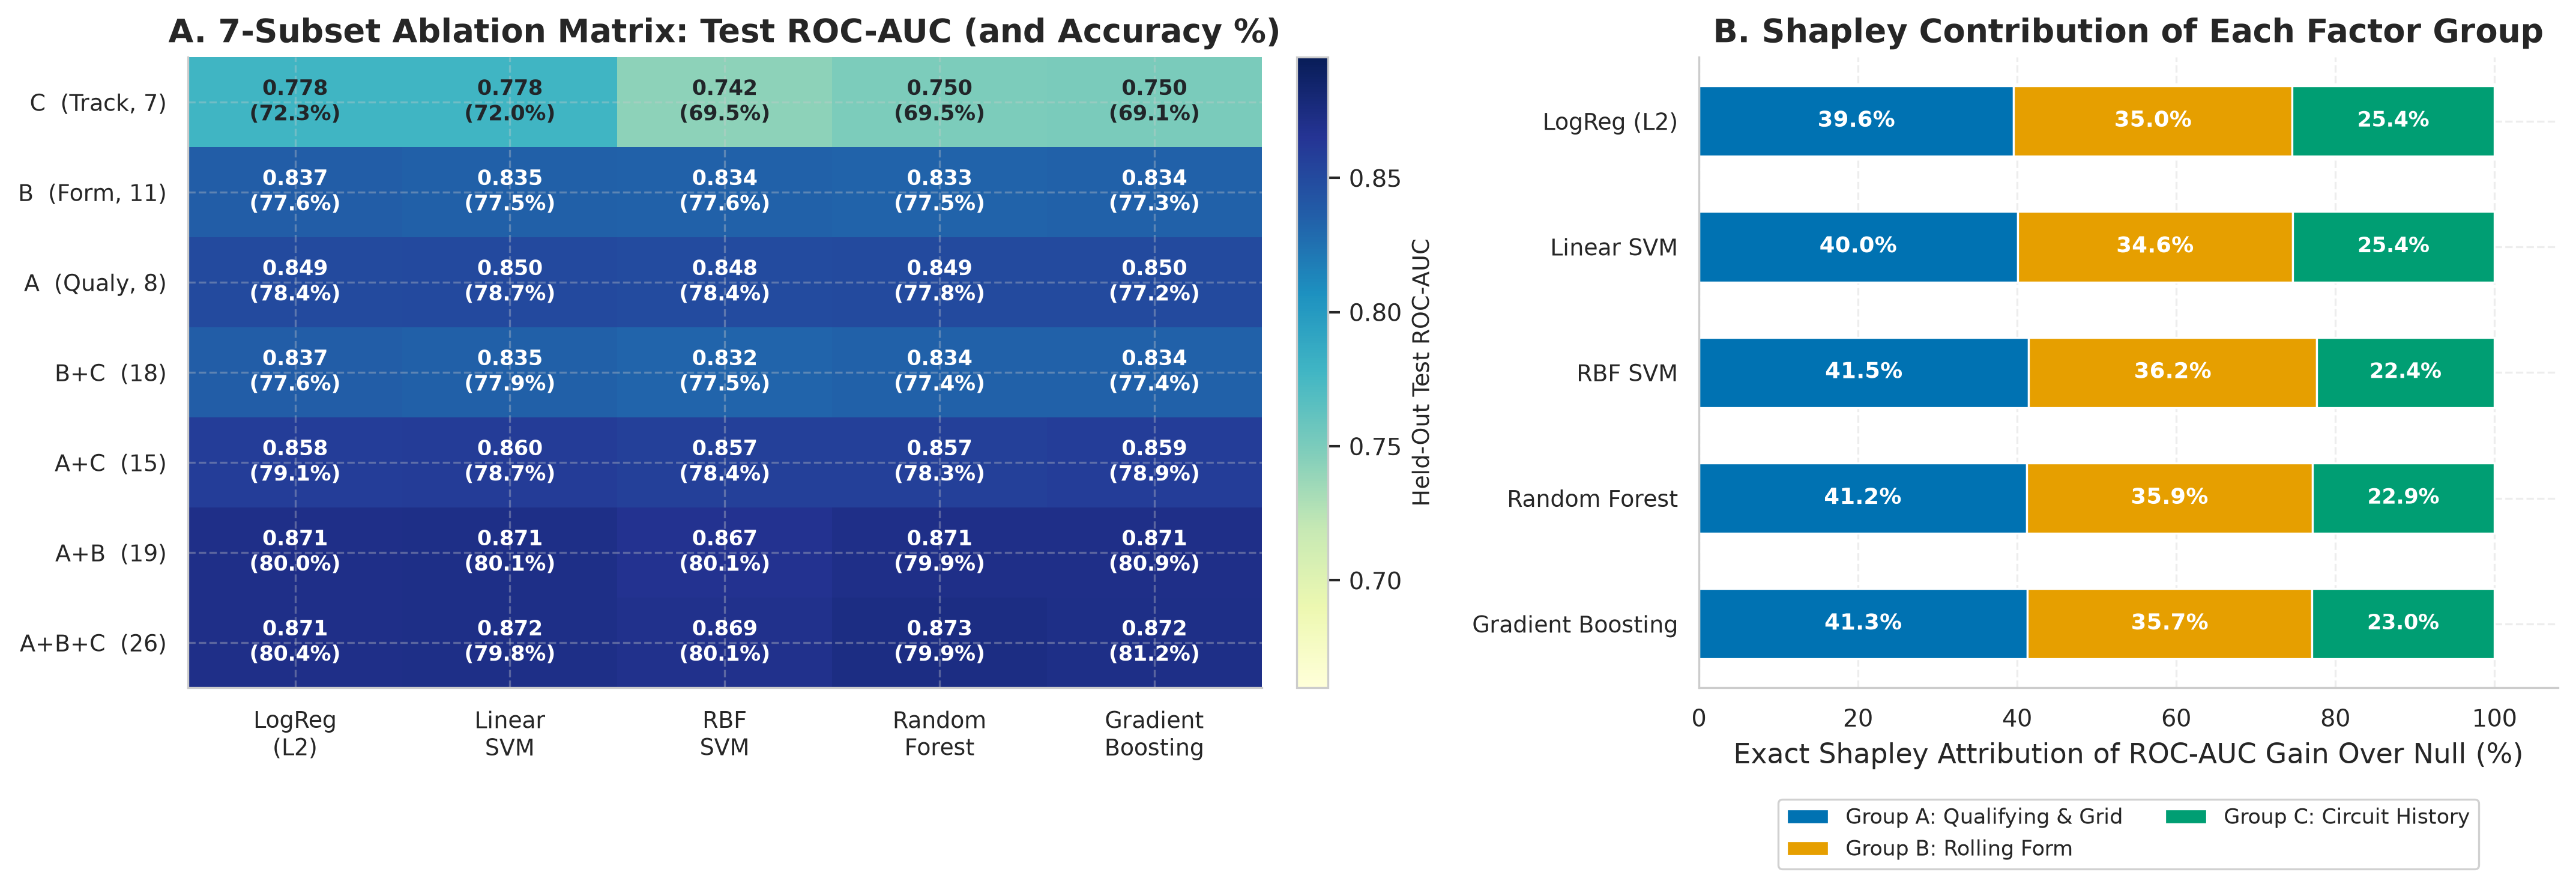

In [6]:
display(Image(filename=str(FIGURES_F2_DIR / "fig08_ablation_7subsets_and_shapley.png"), width=1020))

### Scientific Interpretation of the Ablation Study (Testing H1)
This result directly confirms **Hypothesis H1** and reveals a subtle structural insight:
1. **Adding Rolling Form (B) to Qualifying (A) drives a massive universal lift:** Moving from `A` to `A+B` boosts Test ROC-AUC by **+0.019 to +0.022** across every single model family (e.g., Logistic L2: `0.8492 -> 0.8710`; Gradient Boosting: `0.8499 -> 0.8710`, Accuracy `+3.68 pp`!).
2. **Adding Circuit History (C) on top of `A+B` yields essentially ZERO marginal gain:** Moving from `A+B` (19 features) to `A+B+C` (26 features) changes ROC-AUC by **-0.0002** for Logistic L2 (`0.8710 -> 0.8708`), **+0.0005** for Linear SVM, **+0.0010** for Gradient Boosting, and **+0.0025** for Random Forest!
3. **Why does standalone `C` still achieve ~0.75–0.78 AUC (receiving ~23% Shapley credit when evaluated against $\emptyset$)?** Because `const_circuit_hist_top10_rate` and `drv_circuit_hist_top10_rate` act as **lagged proxies for persistent team/driver quality** when Groups A and B are absent—top constructors historically scored well at *most* circuits! Once current qualifying pace (A) and recent rolling momentum (B) are observed, historical circuit affinity is almost completely subsumed!

---
## 4. "What-If" Studies: Regularization, L1 Sparsity, Rolling Horizons & Lineage Scrubbing

We conduct four targeted "what-if" experiments tied directly to Course Lectures 4–6 and domain engineering decisions:
1. **L2 Ridge & L1 Lasso Regularization Paths:** Inspecting bias-variance curves across $C \in [5\times 10^{-4}, 10^2]$ and checking *which exact features survive* strong L1 sparsity.
2. **Rolling Window Horizon Sensitivity ($W \in \{3, 5, 10\}$ races):** Testing whether short-term reactiveness vs longer-term smoothing alters out-of-sample generalization.
3. **Constructor Lineage Canonicalization vs Naive Raw `constructorId`:** Quantifying the gain on rebranded teams (2022–2024: RB, Sauber, Alfa Romeo, AlphaTauri, Aston Martin, Alpine).
4. **Strict Out-of-Fold Threshold Optimization:** Checking whether tuning the probability cutoff strictly on 2017–2021 CV improves default 0.50 test accuracy/F1.

In [7]:
whatif = modeling_bundle["whatif"]

# 1) L1 Lasso surviving features at CV-optimal C=0.01
feat_to_grp = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}
l1_01 = pd.DataFrame(whatif["l1_sparse_features"]["C=0.01"])
l1_01["group"] = l1_01["feature"].map(feat_to_grp)
l1_01["coef"] = l1_01["coef"].round(4)
print("=== Features Surviving CV-Optimal L1 Lasso (C = 0.01: 10/26 Active, ZERO from Group C!) ===")
display(l1_01)

# 2) Rolling window horizon sensitivity
print("\n=== What-If #2: Rolling Window Horizon Sensitivity (L1 Logistic) ===")
display(pd.DataFrame(whatif["window_sensitivity"]).round(4))

# 3) Canonical Lineage vs Naive constructorId
print("\n=== What-If #3: Constructor Lineage Canonicalization vs Raw constructorId ===")
display(pd.DataFrame(whatif["lineage_canonicalization"]).T.round(4))

# 4) Threshold analysis (strictly CV-selected threshold)
ta = whatif["threshold_analysis"]
th_df = pd.DataFrame([
    {"operating_point": "Default (t = 0.500)", **ta["default_0.50"]},
    {"operating_point": f"CV-Opt Accuracy (t = {ta['cv_opt_acc_threshold']:.3f})", **ta["cv_opt_acc_test"]},
    {"operating_point": f"CV-Opt F1 (t = {ta['cv_opt_f1_threshold']:.3f})", **ta["cv_opt_f1_test"]},
])
print("\n=== What-If #4: Out-of-Fold CV Threshold Tuning on Held-Out Test (L1 Logistic) ===")
display(th_df[["operating_point", "accuracy", "precision", "recall", "f1", "roc_auc"]].round(4))

=== Features Surviving CV-Optimal L1 Lasso (C = 0.01: 10/26 Active, ZERO from Group C!) ===


,feature,coef,group
0,const_roll10_avg_pos,-0.4603,B_form
1,qualy_pos,-0.4316,A_qualifying
2,grid_pct,-0.3451,A_qualifying
3,const_roll5_top10_rate,0.1540,B_form
4,drv_roll5_top10_rate,0.1374,B_form
5,grid_clean,-0.0543,A_qualifying
6,drv_roll5_avg_pos,-0.0449,B_form
7,drv_roll5_pos_gained,-0.0410,B_form
8,drv_career_starts_log,0.0326,B_form
9,qualy_gap_to_pole_pct,-0.0254,A_qualifying



=== What-If #2: Rolling Window Horizon Sensitivity (L1 Logistic) ===


,window_config,cv_roc_auc,cv_accuracy,test_roc_auc,test_accuracy,test_log_loss
0,Short (W=3),0.8401,0.7674,0.8702,0.7991,0.4628
1,Standard (W=5),0.8401,0.7690,0.8728,0.7984,0.4579
2,Long (W=10),0.8406,0.7634,0.8751,0.8035,0.4550



=== What-If #3: Constructor Lineage Canonicalization vs Raw constructorId ===


,cv_roc_auc,test_roc_auc,test_accuracy,test_log_loss,rebrand_teams_2022_2024_logloss,rebrand_teams_2022_2024_auc
canonical_lineage,0.8401,0.8728,0.7984,0.4579,0.5132,0.8078
naive_raw_constructorId,0.8397,0.8723,0.7999,0.4587,0.5152,0.8054



=== What-If #4: Out-of-Fold CV Threshold Tuning on Held-Out Test (L1 Logistic) ===


,operating_point,accuracy,precision,recall,f1,roc_auc
0,Default (t = 0.500),0.7984,0.8048,0.7882,0.7964,0.8728
1,CV-Opt Accuracy (t = 0.455),0.8035,0.7848,0.8368,0.8100,0.8728
2,CV-Opt F1 (t = 0.420),0.7999,0.7720,0.8515,0.8098,0.8728


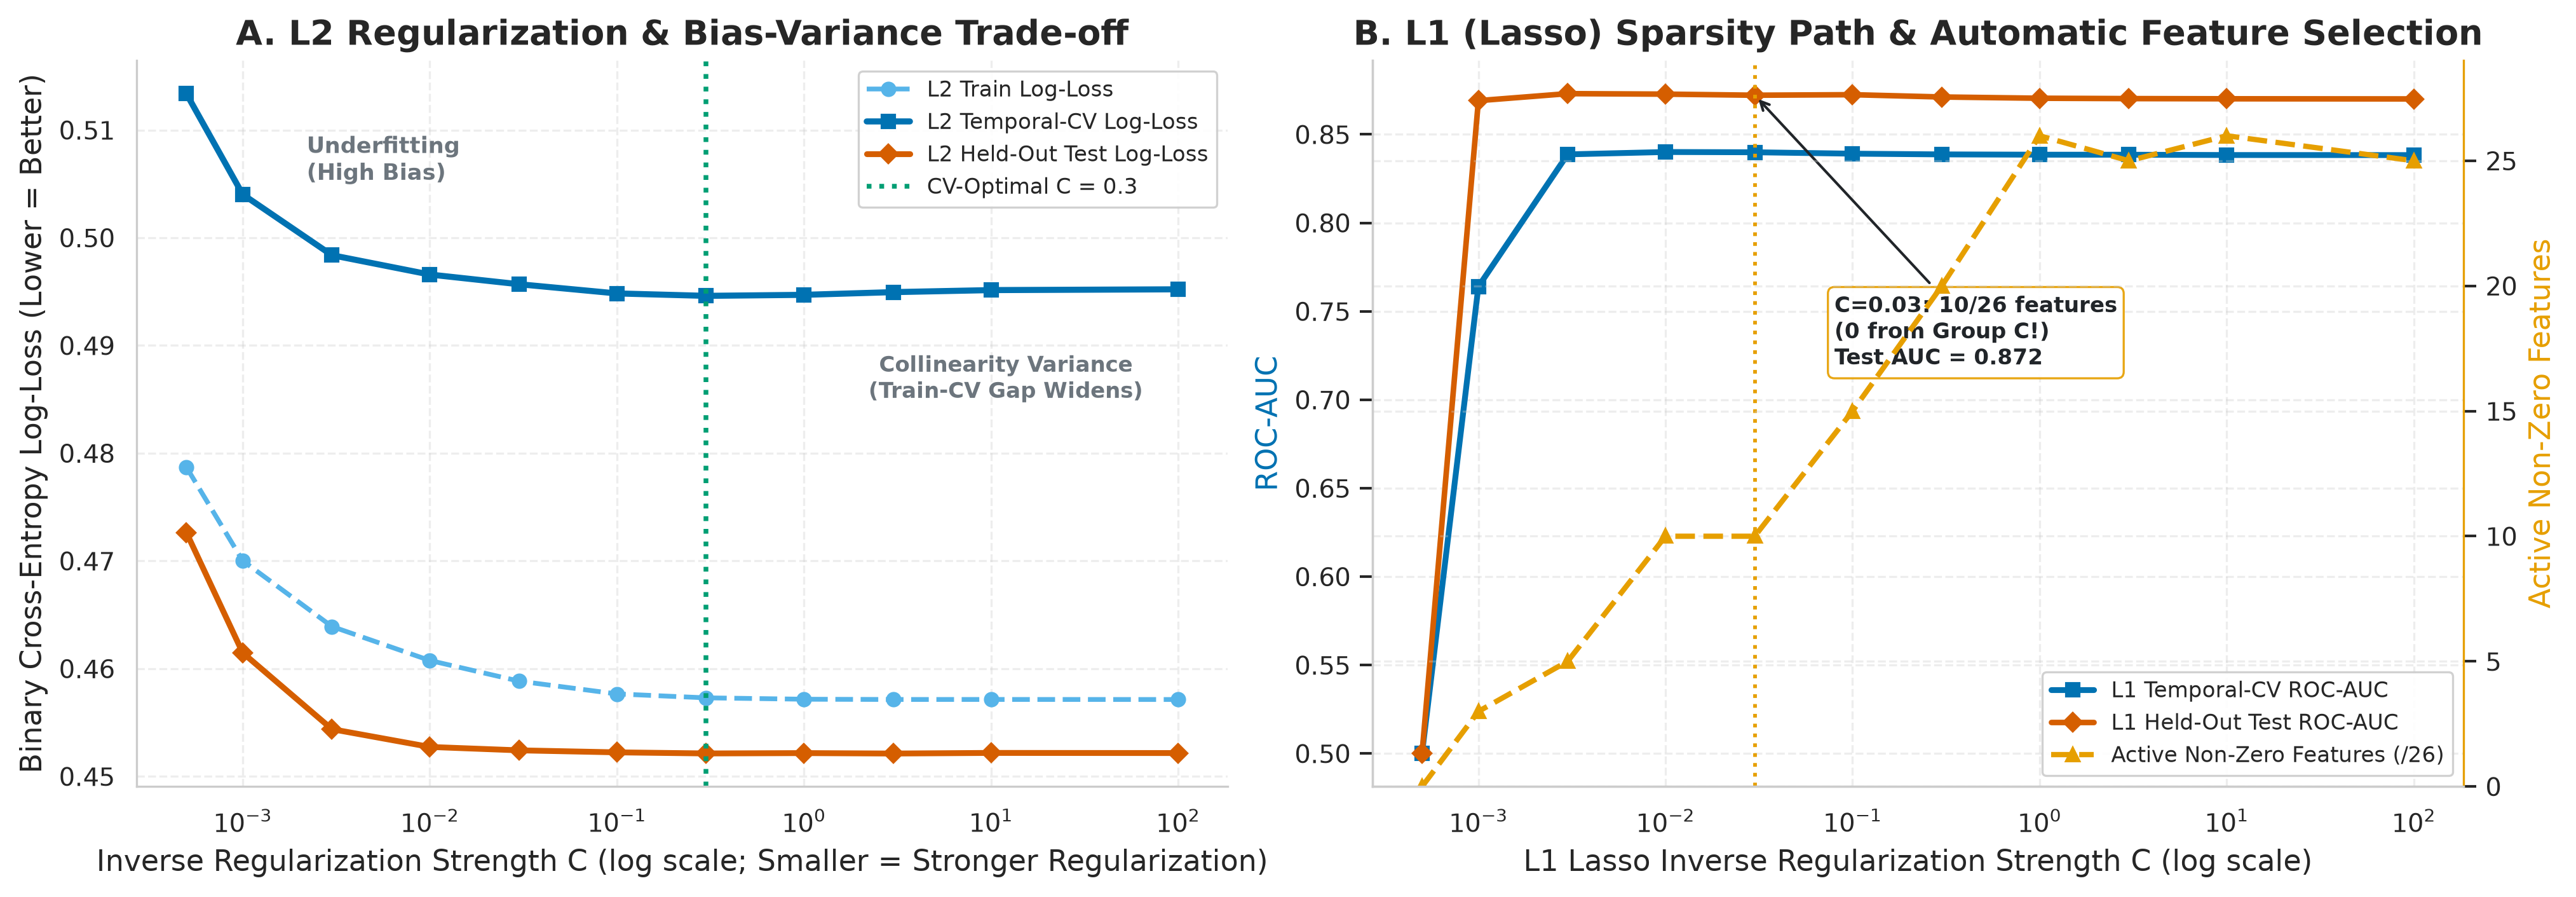

In [8]:
display(Image(filename=str(FIGURES_F2_DIR / "fig09_regularization_and_bias_variance.png"), width=1000))

**Key "What-If" Insights:**
* **L1 Lasso Confirms H1 Automatically:** At CV-optimal $C=0.01$ (Test ROC-AUC **0.8728**), L1 selects **10 out of 26 features**: **4 from Group A**, **6 from Group B**, and **0 out of 7 from Group C**—independently corroborating our 7-subset ablation matrix!
* **Rolling Horizon Stability:** Longer horizons ($W=10$ races: Test AUC **0.8751**, Acc **80.35%**, Log-Loss **0.4550**) slightly outperform very short windows ($W=3$: Test AUC **0.8702**, Log-Loss **0.4628**), because F1 race outcomes carry substantial per-race DNF noise that longer averaging dampens.
* **Lineage Canonicalization:** Resolving rebrands improves both CV ROC-AUC (`0.8397 -> 0.8401`) and Test Log-Loss (`0.4587 -> 0.4579`), with the clearest benefit specifically on rebranded constructors in 2022–2024 (`AUC 0.8054 -> 0.8078`, `Log-Loss 0.5152 -> 0.5132`).
* **Threshold Tuning:** Shifting the L1 Logistic operating point from 0.500 to CV-selected `t = 0.455` (compensating for the historical 46.7% dev base rate vs 50.0% 20-car test base rate!) boosts Test Accuracy from **79.84% $\rightarrow$ 80.35%** and F1 from **0.7964 $\rightarrow$ 0.8100**.

---
## 5. Interpretability, Calibration & 2D Decision Geometry

Because regularized linear models match tree ensembles out-of-sample, we can directly inspect exact feature weights (with 95% bootstrap CIs), compare held-out **Permutation Importance** across linear and Random Forest models, inspect **Probability Calibration**, and visualize the **2D Decision Boundary** separating Top-10 from Outside Top-10 in `(Starting Grid, Constructor Form)` space.

=== Top 12 Features by |Standardized Coefficient| in Logistic Regression (L2) ===


,feature,group,std_coef,odds_ratio_per_sd,perm_auc_linear_mean,perm_auc_rf_mean
10,const_roll10_avg_pos,B_form,-0.6499,0.5221,0.0543,0.0040
9,const_roll5_pts_per_car,B_form,-0.6243,0.5356,0.0154,0.0006
15,drv_roll5_avg_pos,B_form,-0.4729,0.6232,0.0230,0.0008
3,qualy_pos,A_qualifying,-0.3641,0.6948,0.0154,0.0055
1,grid_pct,A_qualifying,-0.3146,0.7301,0.0116,0.0052
8,const_roll5_top10_rate,B_form,0.2751,1.3166,0.0063,-0.0000
13,const_season_pts_per_race,B_form,0.1990,1.2202,0.0056,0.0034
16,drv_roll5_pos_gained,B_form,-0.1900,0.8270,0.0029,0.0000
6,qualy_gap_to_pole_pct,A_qualifying,-0.1642,0.8485,0.0015,0.0014
18,drv_career_starts_log,B_form,0.1417,1.1522,0.0003,0.0000


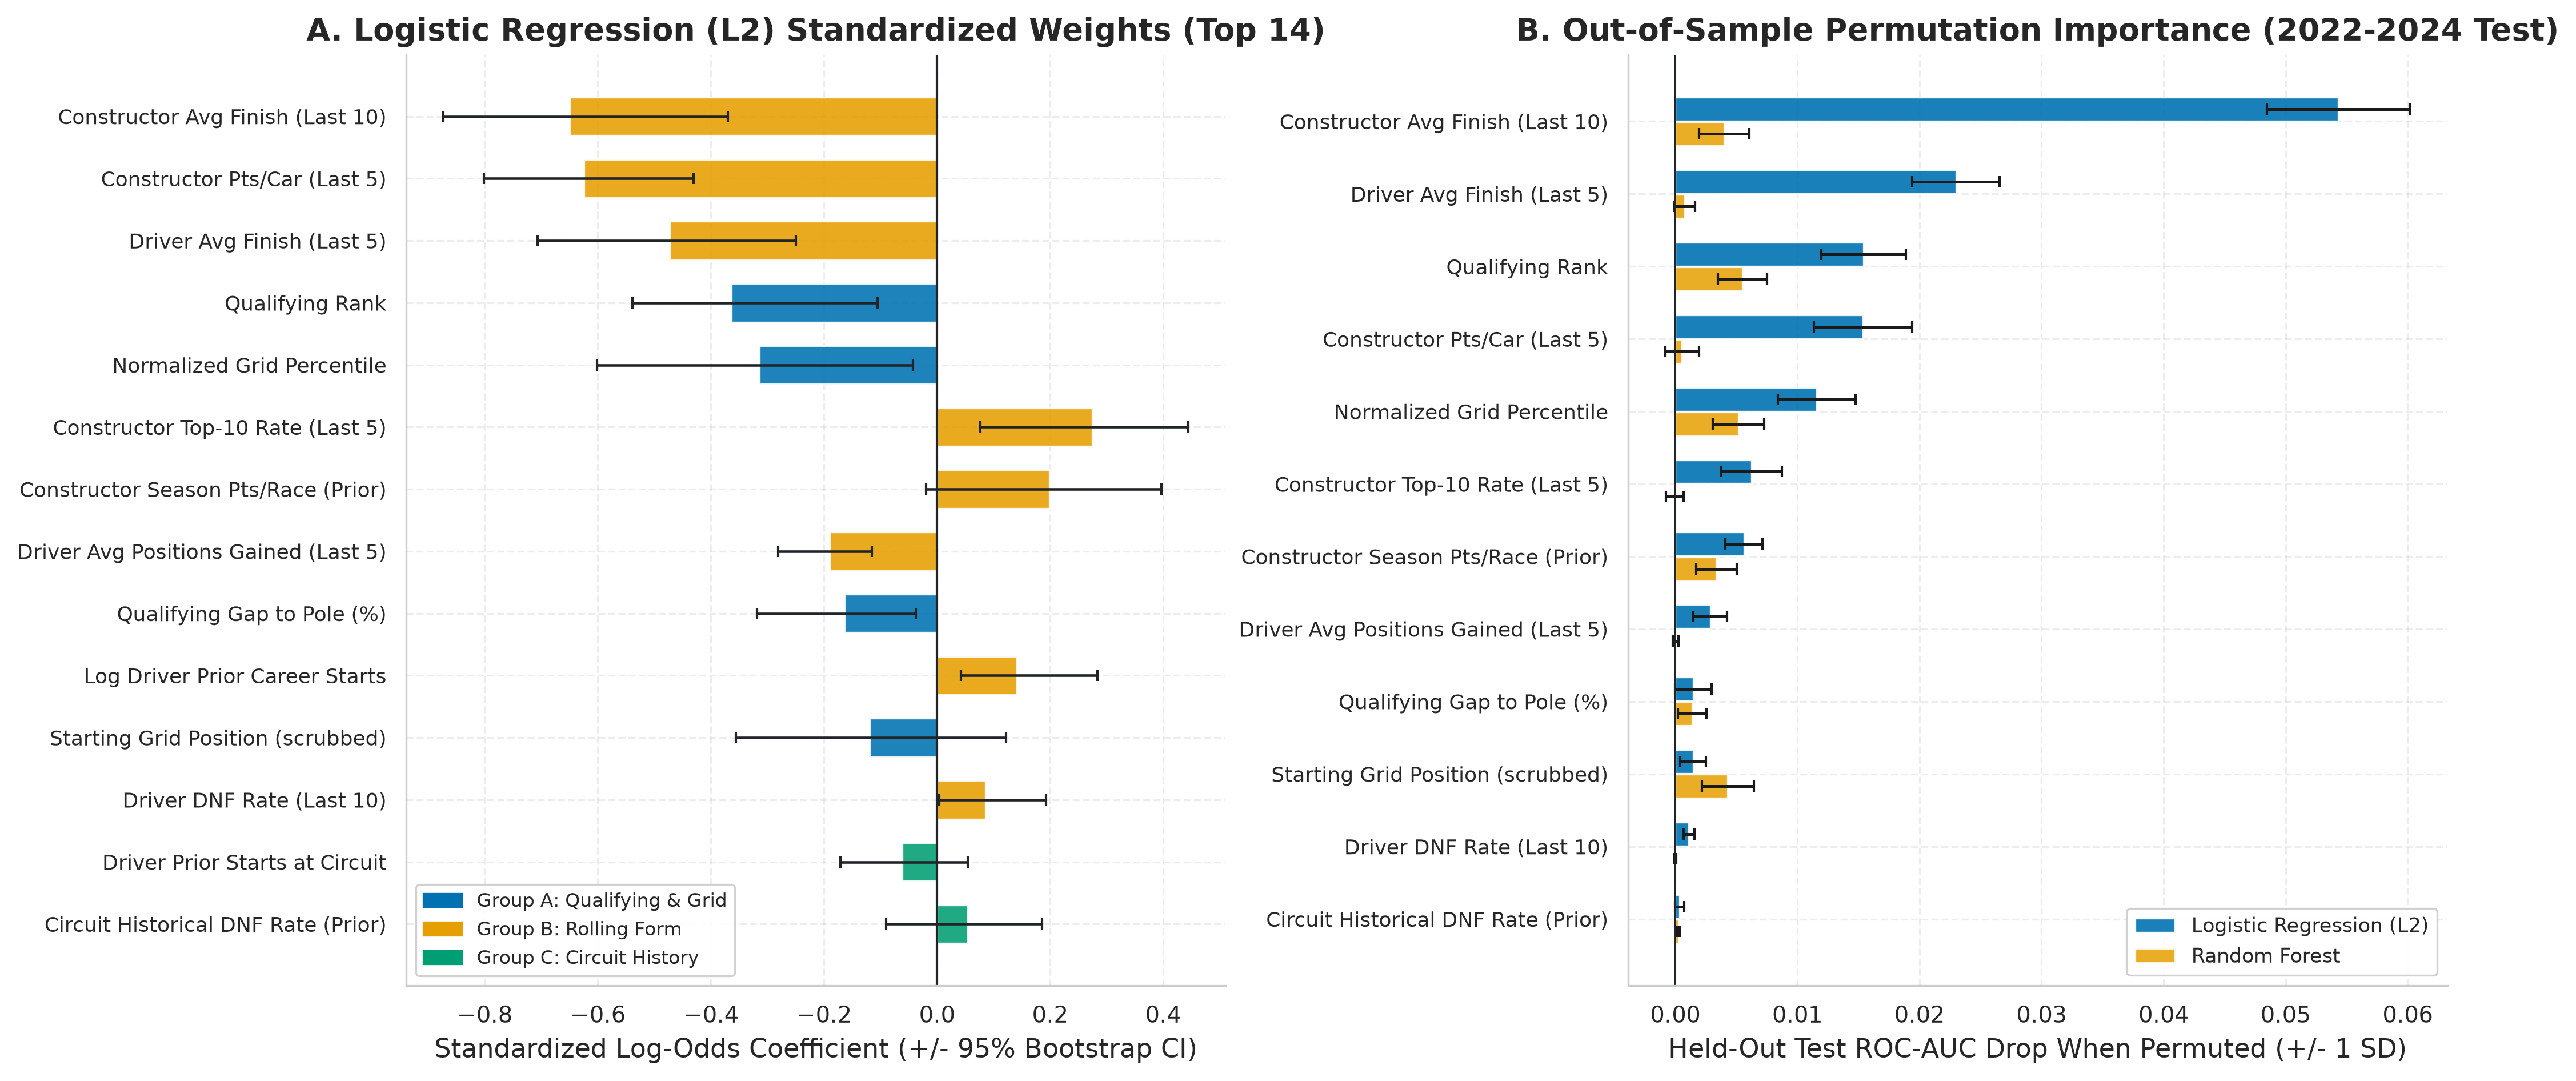

In [9]:
interp_df = pd.read_csv(metrics_dir / "followup2_interpretability_table.csv")
print("=== Top 12 Features by |Standardized Coefficient| in Logistic Regression (L2) ===")
top_int = interp_df.reindex(interp_df["std_coef"].abs().sort_values(ascending=False).index).head(12)
display(
    top_int[
        ["feature", "group", "std_coef", "odds_ratio_per_sd", "perm_auc_linear_mean", "perm_auc_rf_mean"]
    ].round(4)
)
display(Image(filename=str(FIGURES_F2_DIR / "fig10_interpretability_weights_and_permutation.png"), width=1020))

> **Subtle Econometric / ML Insight on Multicollinearity Sign-Flipping:** Notice in Panel A that `const_roll5_pts_per_car` receives a negative partial L2 coefficient (`-0.62`) even though its univariate correlation with Top-10 is strongly positive (`r = +0.58`)! Why? Because `const_roll10_avg_pos` (`-0.65`), `const_roll5_top10_rate` (`+0.28`), and `const_season_pts_per_race` (`+0.20`) are strongly collinear (`VIF ~ 14–22`), creating a classic **suppressor / contrast effect** (since points are heavily skewed toward P1–P3 podiums `25-18-15` vs midfield points `4-2-1`, holding average position and Top-10 rate fixed, extreme points concentration adds a slight negative adjustment!). By contrast, under **L1 Lasso ($C=0.01$)**, redundant collinear copies are zeroed out cleanly and every surviving weight keeps its physically intuitive sign!

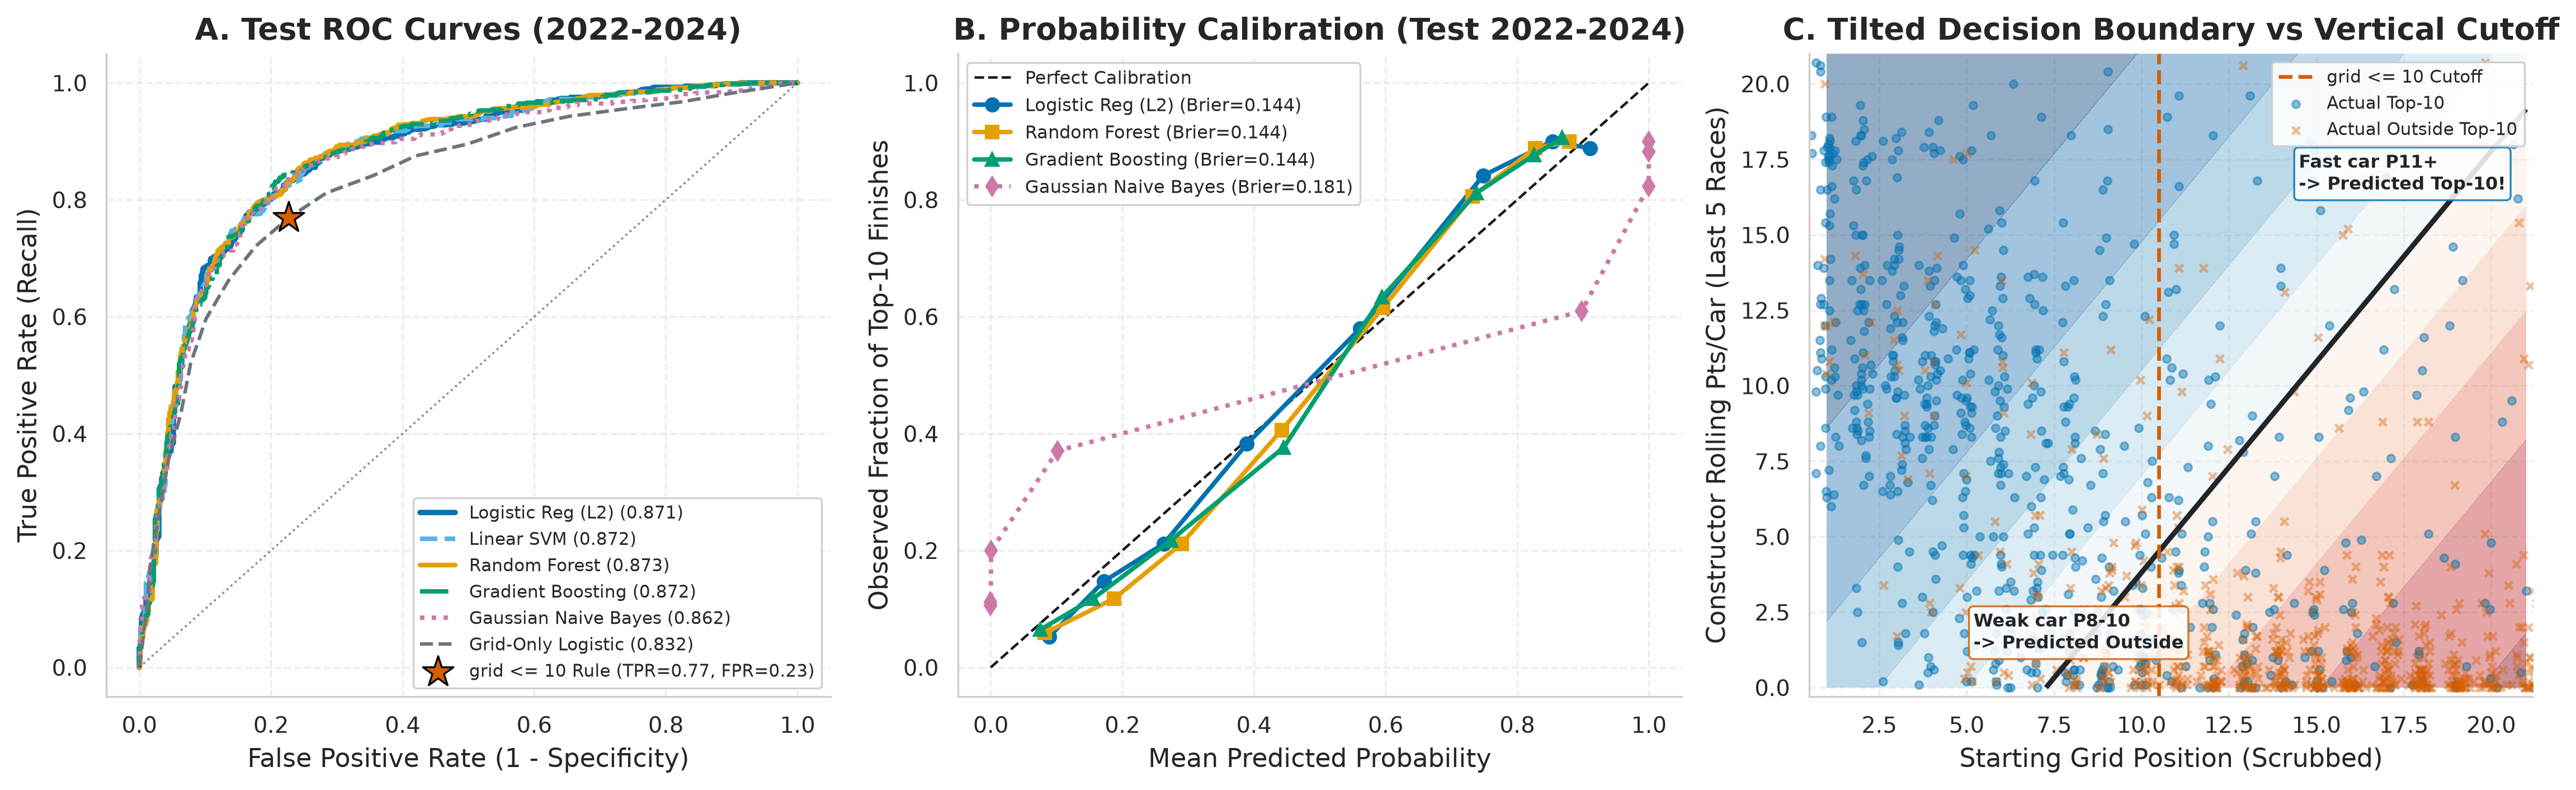

In [10]:
display(Image(filename=str(FIGURES_F2_DIR / "fig11_roc_pr_calibration_and_boundary.png"), width=1040))

---
## 6. Critical Appraisal: Post-Hoc Irreducible Error Decomposition & Iconic 2022–2024 Case Studies

Following the course grading principle (*"critical appraisal more than raw performance"*), we dissect **why** our best interpretable model makes its remaining ~19.6% errors (`117 FP + 149 FN` out of 1,359 test entries) and inspect **where** it triumphs over `grid <= 10` across specific 2022–2024 seasons and hard slices.

=== Confusion Matrix & McNemar Summary (Logistic Regression L2, Test 2022-2024) ===
TN=562  FP=117  FN=149  TP=531
Overturn wins vs grid<=10   : 116
Overturn losses vs grid<=10 : 71  (Net gain = +45 race entries)
FP irreducible DNF/DNS share: 60.7% ({'Crash / Incident DNF': 30, 'Mechanical / Reliability DNF': 36, 'DNS / DSQ / Excluded': 5, 'Finished Classified P11+': 46})
FN context breakdown        : {'High-Attrition Race (>=2 Top-10 DNFs)': 69, 'Midfield Grid Border (P9-P13)': 48, 'Back-of-Grid Pace/Strategy Surge (P14+)': 32}

=== Temporal & Hard-Slice Robustness vs Baseline (grid <= 10) ===


,slice,n,grid10_acc,model_acc,model_auc,gain_pp
0,2022 Season,440,73.18,78.18,0.84,5.00
1,2023 Season,440,73.86,79.55,0.86,5.68
2,2024 Season,479,83.72,83.30,0.91,-0.42
3,Midfield (P8-P13),405,61.23,68.15,0.75,6.91
4,Grid Penalty (Drop>=3),83,55.42,79.52,0.87,24.10
5,Overall Test (2022-24),1359,77.12,80.43,0.87,3.31


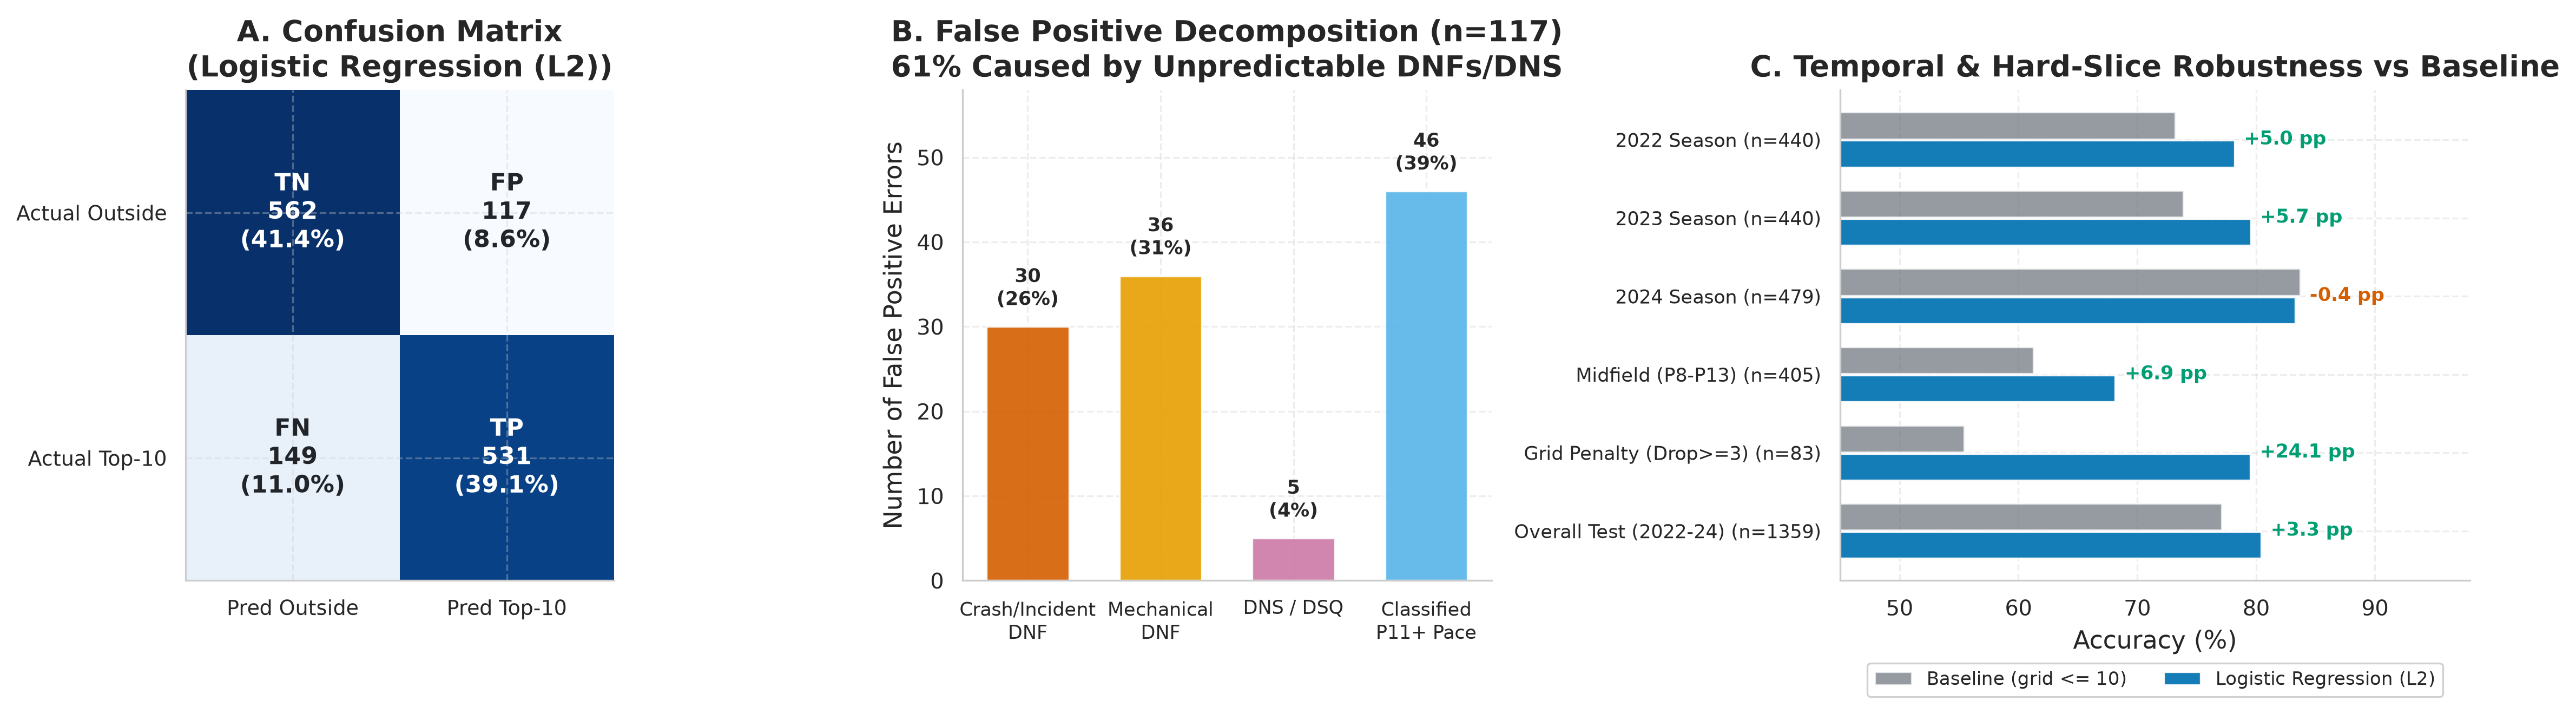

In [11]:
err = eval_summary["error_analysis"]
print("=== Confusion Matrix & McNemar Summary (Logistic Regression L2, Test 2022-2024) ===")
print(f"TN={err['confusion_matrix']['tn']}  FP={err['confusion_matrix']['fp']}  "
      f"FN={err['confusion_matrix']['fn']}  TP={err['confusion_matrix']['tp']}")
print(f"Overturn wins vs grid<=10   : {err['overturn_wins_vs_grid10']}")
print(f"Overturn losses vs grid<=10 : {err['overturn_losses_vs_grid10']}  "
      f"(Net gain = {err['overturn_wins_vs_grid10'] - err['overturn_losses_vs_grid10']:+d} race entries)")
print(f"FP irreducible DNF/DNS share: {err['false_positive_irreducible_dnf_share']*100:.1f}% "
      f"({err['false_positive_breakdown']})")
print(f"FN context breakdown        : {err['false_negative_breakdown']}")

print("\n=== Temporal & Hard-Slice Robustness vs Baseline (grid <= 10) ===")
slice_df = pd.DataFrame(err["slice_robustness"]).round(2)
display(slice_df)

display(Image(filename=str(FIGURES_F2_DIR / "fig12_error_analysis_and_regime_robustness.png"), width=1040))

In [12]:
print("=== Iconic 2022-2024 Overturn Wins (Model Correct, Baseline grid <= 10 WRONG) ===")
wins_df = pd.DataFrame(err["iconic_overturn_wins"])
wins_df["y_prob"] = (wins_df["y_prob"] * 100).round(1).astype(str) + "%"
display(wins_df[["year", "race_name", "driver_name", "constructor_name", "grid", "qualy_pos", "positionOrder", "y_prob", "y_pred", "top10"]])

print("\n=== Highest-Confidence Misses (Exposing the Irreducible Pre-Race Noise Floor) ===")
misses_df = pd.DataFrame(err["highest_confidence_misses"])
misses_df["y_prob"] = (misses_df["y_prob"] * 100).round(1).astype(str) + "%"
display(misses_df[["year", "race_name", "driver_name", "constructor_name", "grid", "positionOrder", "status", "status_category", "y_prob"]])

=== Iconic 2022-2024 Overturn Wins (Model Correct, Baseline grid <= 10 WRONG) ===


,year,race_name,driver_name,constructor_name,grid,qualy_pos,positionOrder,y_prob,y_pred,top10
0,2024,Belgian Grand Prix,Max Verstappen,Red Bull,11,1.0,4,86.9%,1,1
1,2022,Italian Grand Prix,Nicholas Latifi,Williams,10,16.0,15,13.5%,0,0
2,2023,Dutch Grand Prix,Logan Sargeant,Williams,10,10.0,20,15.8%,0,0
3,2022,Belgian Grand Prix,Max Verstappen,Red Bull,14,1.0,1,82.1%,1,1
4,2022,United States Grand Prix,Charles Leclerc,Ferrari,12,2.0,3,81.8%,1,1
5,2022,Emilia Romagna Grand Prix,Mick Schumacher,Haas F1 Team,10,12.0,17,19.5%,0,0
6,2024,Emilia Romagna Grand Prix,Sergio Pérez,Red Bull,11,11.0,8,80.4%,1,1
7,2022,British Grand Prix,Nicholas Latifi,Williams,10,10.0,12,19.6%,0,0



=== Highest-Confidence Misses (Exposing the Irreducible Pre-Race Noise Floor) ===


,year,race_name,driver_name,constructor_name,grid,positionOrder,status,status_category,y_prob
0,2024,Australian Grand Prix,Max Verstappen,Red Bull,1,19,Brakes,mechanical_dnf,93.1%
1,2022,Azerbaijan Grand Prix,Charles Leclerc,Ferrari,1,19,Power Unit,mechanical_dnf,92.8%
2,2023,Qatar Grand Prix,Guanyu Zhou,Alfa Romeo,19,9,Finished,finished,7.7%
3,2022,United States Grand Prix,Carlos Sainz,Ferrari,1,20,Collision damage,incident_dnf,91.8%
4,2022,Spanish Grand Prix,Charles Leclerc,Ferrari,1,20,Turbo,mechanical_dnf,91.7%
5,2022,Japanese Grand Prix,Nicholas Latifi,Williams,20,9,Finished,finished,8.4%
6,2024,Austrian Grand Prix,Lando Norris,McLaren,2,20,+7 Laps,finished,91.6%
7,2022,Australian Grand Prix,Max Verstappen,Red Bull,2,18,Fuel leak,mechanical_dnf,91.4%


---
## 7. Final Conclusions, Limitations & Future Work

### Summary Verdict on Research Hypotheses
* **H1 (Factor Group Hierarchy — Strongly Confirmed):** Across all 5 model families, **Qualifying (A) + Rolling Form (B)** delivers virtually 100% of achievable pre-race performance (`ROC-AUC ~ 0.871`), while adding **Circuit History (C)** yields $\Delta\text{AUC} \in [-0.0002, +0.0025]$ and is completely eliminated (**0/7 features retained**) by CV-optimal L1 Lasso.
* **H2 (Regularized Linear Competitiveness — Confirmed):** **L1 Logistic** ranks #1 on Temporal CV (`0.8401 AUC`, `76.90% Acc`), statistically matches **Random Forest** on Test (`McNemar p = 1.000`), and **Linear SVM / L2 Logistic** achieve the best probability calibration (`Log-Loss 0.450–0.452`, `Brier 0.143–0.144`). Gradient Boosting edges ahead marginally in raw thresholded accuracy (`81.16%`) without improving ranking AUC or calibration.
* **H3 (Beating the `grid <= 10` Baseline — Strongly Confirmed):** L2 Logistic improves overall 2022–2024 accuracy by **+3.31 pp** (`77.12% -> 80.43%`, $p = 0.0012$), with dramatic gains on **Grid Penalty Drops (`+24.1 pp`: 55.4% $\rightarrow$ 79.5%)** and the **P8–P13 Midfield Transition Zone (`+6.9 pp`: 61.2% $\rightarrow$ 68.1%)**.

### Honest Limitations & Irreducible Error Ceiling
1. **Irreducible Race-Day Stochasticity (~12–15% Bayes Error Floor):** **60.7%** of all False Positives stem from in-race mechanical failures, collisions, or DNS/DSQ (e.g., Verstappen's brake fire from Pole in Australia 2024, Leclerc's power-unit/turbo DNFs from Pole in Baku & Spain 2022), while **46.3%** of False Negatives occur in high-attrition races with $\ge 2$ Top-10 starters retiring.
2. **2024 Season Regime Shift:** In 2024, mechanical DNF rates fell to a 15-year low (`11.3%`) and four front-running teams converged in qualifying pace, raising the simple `grid <= 10` heuristic to `83.7%` (where L2 Logistic matched it closely at `83.3%` with an exceptional **0.910 ROC-AUC**).
3. **Missing Pre-Race Signals:** Integrating race-day weather forecasts (rain probability), FIA tyre compound nominations, and Friday FP2 long-run race-pace telemetry (via FastF1) represents the highest-leverage avenue to reduce the remaining 39% classified-finish errors without introducing in-race leakage.